In [1]:
import numpy as np
import gymnasium as gym
import torch

from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
import matplotlib.pyplot as plt
# The "ipympl" backend is better, as it allows for interactiveness, but on some installations it does not work, then use "inline"
%matplotlib ipympl
# %matplotlib inline  

# this way of importing allow to reload/refresh the module later with importlib.reload(policy)
import policy as policy 
import memory as mem
from feedforward import Feedforward

Load environment, policy and memory.

In [2]:
env = gym.make('Pendulum-v1', g=9.81, render_mode="human")
pi = policy.PDPolicy(env)
buffer = mem.Memory()

## Inspect the environment 

In [3]:
s , _ = env.reset()
for t in range(100):
    a = pi.get_action(s) 
    s_new, rew, term, trunc, _ = env.step(a)
    buffer.add_transition([s,a,rew,s_new, term, trunc])
    s = s_new
env.close()  # shuts the pygame window down cleanly

<frozen importlib._bootstrap>:488: RuntimeWarning: Your system is avx2 capable but pygame was not built with support for it. The performance of some of your blits could be adversely affected. Consider enabling compile time detection with environment variables like PYGAME_DETECT_AVX2=1 if you are compiling without cross compilation.
amdgpu: amdgpu_query_sw_info(amdgpu_sw_info_address_prt_wa_control_bit) failed.
MESA: error: amdgpu: ac_query_gpu_info failed.
MESA-EGL: warning: egl: failed to create dri2 screen
amdgpu: amdgpu_query_sw_info(amdgpu_sw_info_address_prt_wa_control_bit) failed.
MESA: error: amdgpu: ac_query_gpu_info failed.
MESA-EGL: warning: egl: failed to create dri2 screen


In [4]:
transitions = buffer.get_all_transitions()
states = np.vstack(transitions[:,0])
actions = transitions[:,1]
rewards = transitions[:,2]

Plot the trajectory: (state, action, reward)
 
 The state is [position-x, position-y, angular velocity] 
 
 **changes are needed**

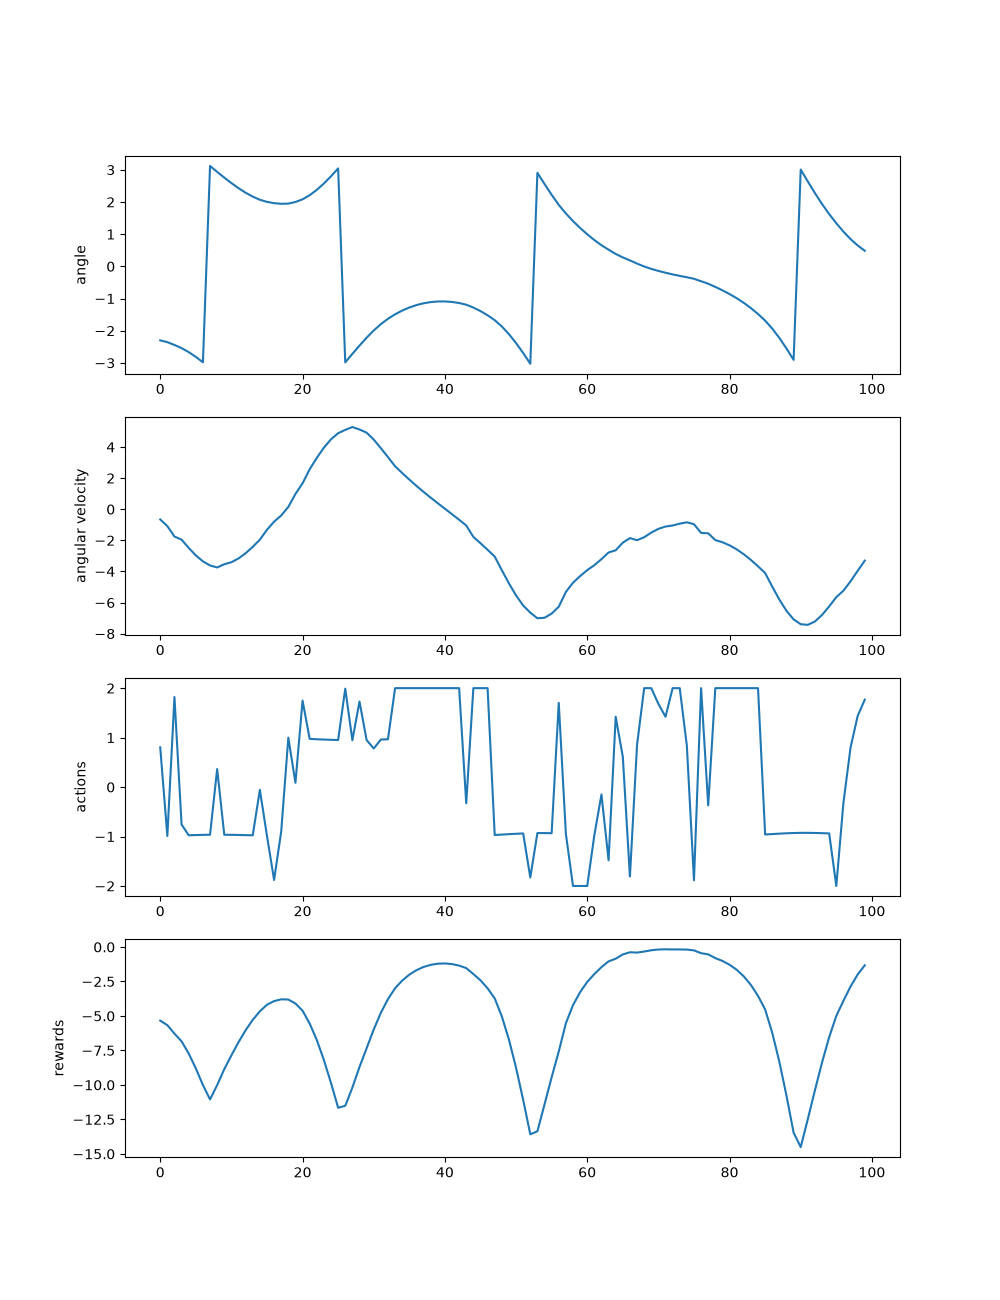

In [5]:
angles = np.arctan2(states[:, 1], states[:, 0])
actions_array = np.array([a[0] for a in actions])

fix, ax = plt.subplots(4, 1, figsize=(10, 13))
ax[0].plot(angles)
ax[0].set_ylabel("angle")
ax[1].plot(states[:, 2])
ax[1].set_ylabel("angular velocity")
ax[2].plot(actions_array)
ax[2].set_ylabel("actions")
ax[3].plot(rewards)
ax[3].set_ylabel("rewards")
plt.show()

# Collect data

We do 500 rollouts a 100 timesteps with the black box policy. Nothing needs to be changed here.

In [6]:
env = gym.make('Pendulum-v1', g=9.81, render_mode=None) # switch off rendering
for ep in range(500):
    # start a larger range initial conditions to see enough of the statespace
    s, _ = env.reset(options={"y_init": 4.0})
    for t in range(100):
        a = pi.get_action(s) 
        s_new, rew, term, trunc, _ = env.step(a)
        buffer.add_transition([s,a,rew,s_new, term, trunc])
        s = s_new

In [7]:
buffer.size

50100

# Fit value function

The value function fitting class. Here, you need to fill in the blank parts

In [8]:
class ValueFunction(Feedforward):
    def __init__(self, observation_dim, hidden_sizes=[100,100]):
        super().__init__(input_size=observation_dim, hidden_sizes=hidden_sizes, output_size=1)
        
        # so this class is already a neural network, see feedforward.py        
        # add and optimizer here (e.g. Adam with lr = 0.0002, eps=0.000001)
        self.optimizer = torch.optim.Adam(self.parameters(), lr=0.0002, eps=0.000001)
        
        # add a loss function here
        self.loss = torch.nn.MSELoss()
    
    def fit(self, observations, targets):
        # Add one training step here. 
        # The states are called here observations        
        self.optimizer.zero_grad()
        
        # Hints:         
        # convert the inputs into torch tensors with torch.from_numpy
        # use self.forward(input) to make a prediction to be used in the loss
        observations_tensor = torch.from_numpy(observations)
        targets_tensor = torch.from_numpy(targets)

        predictions = self.forward(observations_tensor)
        loss = self.loss(predictions, targets_tensor)

        loss.backward()
        self.optimizer.step()
        
        # return the current loss
        return loss.item()

In [9]:
iter_fit = 6000 # do at least 2000
gamma=0.95

In [10]:
valuefunc = ValueFunction(observation_dim=env.observation_space.shape[0])

In [11]:
def plot_value_function(value_function):
    plt.rcParams.update({'font.size': 12})
    xxs =np.linspace(-np.pi/2,np.pi/2)
    yys =np.linspace(-3,3)
    XX,YY=np.meshgrid(xxs,yys)
    dots=np.asarray([np.cos(XX.ravel()),np.sin(XX.ravel()),YY.ravel()]).T
    print(dots.shape)
    # values = np.asarray(test_func(dots)).reshape(XX.shape)
    values =value_function.predict(dots).reshape(XX.shape)

    fig = plt.figure(figsize=[10,8])
    ax = fig.add_subplot(projection='3d')
    surf = ax.plot_surface(XX, YY, values, cmap=cm.coolwarm,
                           linewidth=0, antialiased=False)
    ax.view_init(elev=30, azim=45, roll=0)
    ax.set_xlabel('angle')
    ax.set_ylabel('angle velocity')
    ax.set_zlabel('value')
    # plt.colorbar(cmap=cm.coolwarm)
    return fig

(2500, 3)


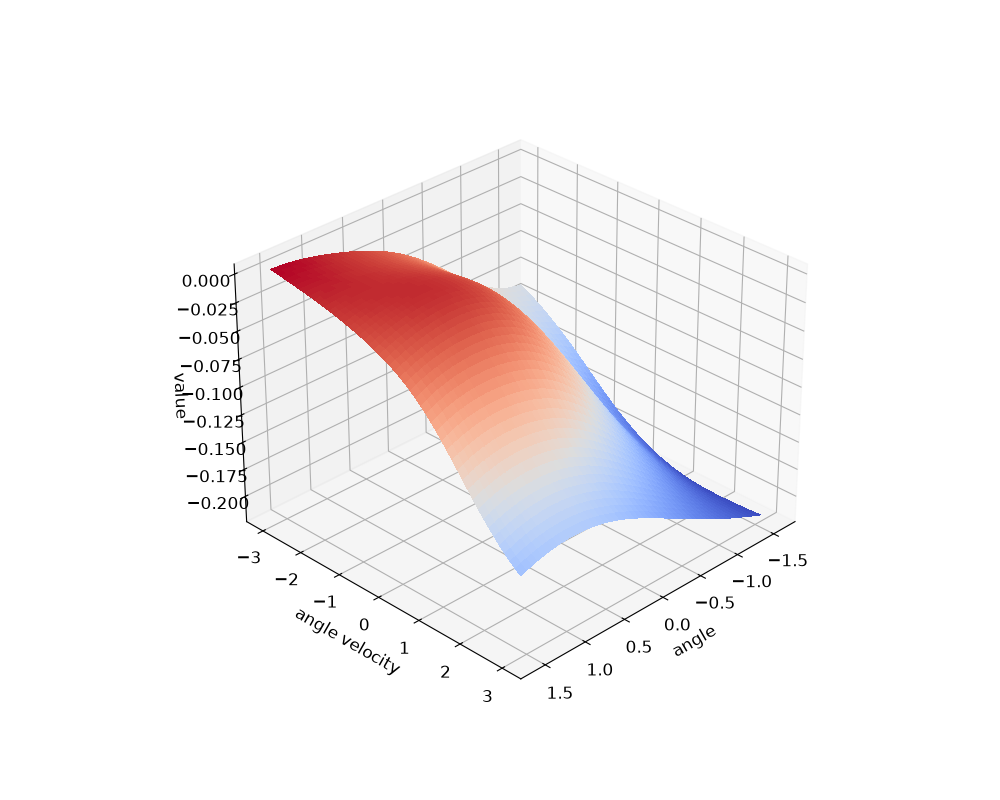

In [12]:

fig = plot_value_function(ValueFunction(observation_dim=env.observation_space.shape[0]))
fig.savefig(f"value_approx_{gamma}_before.pdf", bbox_inches="tight")

Fitting routine of the value function. Fill in the blank parts.

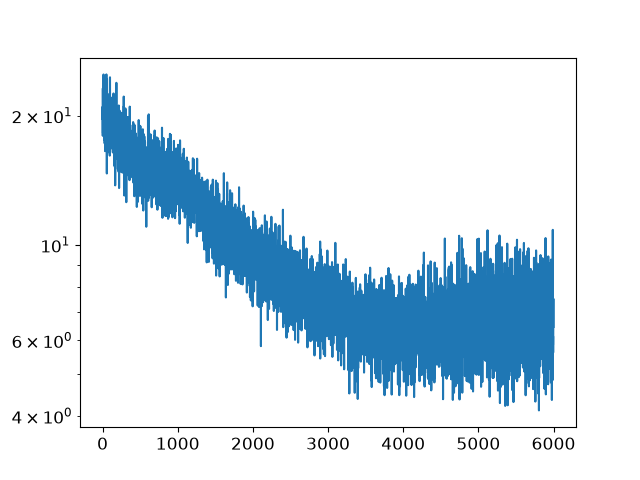

In [13]:
plt_fit = []
for i in range(iter_fit):

    # sample from the replay buffer
    data=buffer.sample(batch=512)
    # each entry in data is (state,action,reward,next_state, term, trunc)    
    
    # Hints:
    #  use can use np.stack to convert the array or arrays into one array
    #  it is really important that you check the shapes of your arrays.
    #  It should be (512,3) for the state and (512,1) for reward and values
    
    states = np.stack(data[:, 0])
    rewards = data[:, 2].reshape(-1, 1)
    term = data[:, 4].reshape(-1, 1).astype(np.int64)

    new_states = np.stack(data[:, 3])
    bootstrapped_values = valuefunc.predict(new_states)

    td_targets = rewards + (1 - term) * gamma * bootstrapped_values
    
    # optimize the least squared objective
    fit_loss = valuefunc.fit(states, td_targets.astype(np.float64))
    
    plt_fit.append(fit_loss)
    
# plot the loss
plt.figure()
plt.yscale("log")
plt.plot(range(len(plt_fit)), plt_fit)

# Visualize

Visualization of the value function. Nothing needs to be changed here.

(2500, 3)


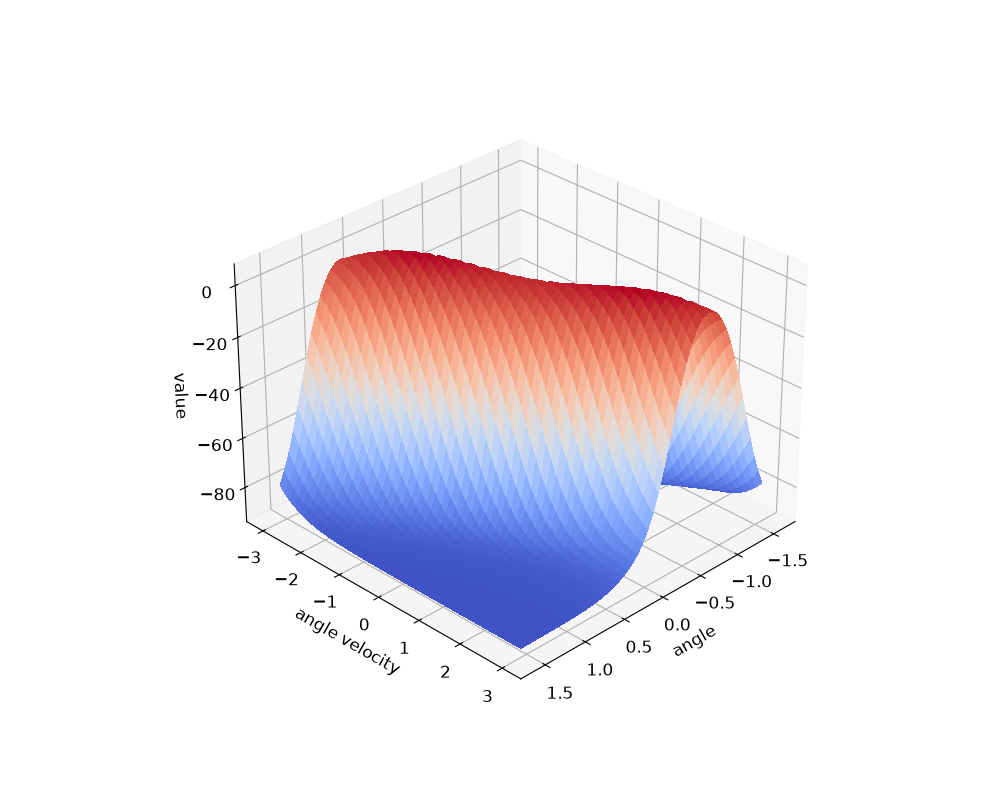

In [14]:
fig = plot_value_function(valuefunc)
fig.savefig(f"value_approx_{gamma}_after.pdf", bbox_inches="tight")